# California Housing Prices (Random Forest Regression)

Random Forest regression on the California Housing dataset, with target-distribution analysis and residual diagnostics.


In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, root_mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import skew

In [16]:
# Load the dataset
data = fetch_california_housing()
X, y = data.data, data.target

In [17]:
print(data.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib:
https://lib.stat.cmu.edu/datasets/houses.zip

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per census
block group. A block g

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [20]:
eda = pd.DataFrame(data=X_train)
eda.columns = data.feature_names
eda['MedHouseVal'] = y_train
eda.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000,16512.000000
mean,3.880754,28.608285,5.435235,1.096685,1426.453004,3.096961,35.643149,-119.582290,2.071947
std,1.904294,12.602499,2.387375,0.433215,1137.056380,11.578744,2.136665,2.005654,1.156226
min,0.499900,1.000000,0.888889,0.333333,3.000000,0.692308,32.550000,-124.350000,0.149990
25%,2.566700,18.000000,4.452055,1.006508,789.000000,2.428799,33.930000,-121.810000,1.198000
50%,3.545800,29.000000,5.235874,1.049286,1167.000000,2.817240,34.260000,-118.510000,1.798500
75%,4.773175,37.000000,6.061037,1.100348,1726.000000,3.280000,37.720000,-118.010000,2.651250
max,15.000100,52.000000,141.909091,25.636364,35682.000000,1243.333333,41.950000,-114.310000,5.000010


Text(0, 0.5, 'Frequency')

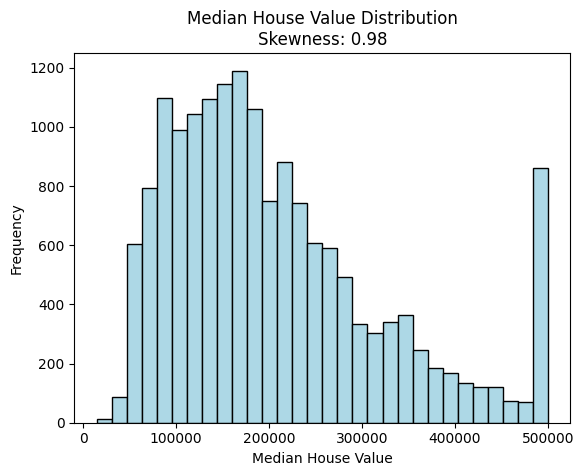

In [21]:
# Plot the distribution
plt.hist(1e5*y_train, bins=30, color='lightblue', edgecolor='black')
plt.title(f'Median House Value Distribution\nSkewness: {skew(y_train):.2f}')
plt.xlabel('Median House Value')
plt.ylabel('Frequency')

The target is skewed to the right (skewness 0.98) and capped at about $500,000, and that cap distorts the data.

Most districts are in the low-to-middle range. The distribution peaks at about $150,000–$180,000. Most values fall between about $70,000 and $250,000.
There's a long right tail. Frequencies fall steadily from about $200,000 to $480,000, with fewer and fewer expensive districts. That tail produces the skewness of 0.98: moderate, but clear.
The spike at $500,000 is caused by a cap. The last bar jumps to about 860 districts, even though the bars just before it are at only about 70. These aren't districts that are all worth exactly $500,000: the dataset caps every value above $500,001. A $700,000 district and a $2M district both appear as $500,001, so their real value is unknown.
Very cheap districts are rare. Only a few are below $50,000, and the minimum is about $15,000.

In [22]:
# Initialize and fit the Random Forest Regressor
rf_regressor = RandomForestRegressor(n_estimators=100, random_state=42)
rf_regressor.fit(X_train, y_train)

# Predict on test set
y_pred_test = rf_regressor.predict(X_test)

In [23]:
mae = mean_absolute_error(y_test, y_pred_test)
mse = mean_squared_error(y_test, y_pred_test)
rmse = root_mean_squared_error(y_test, y_pred_test)
r2 = r2_score(y_test, y_pred_test)
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 0.3277
Mean Squared Error (MSE): 0.2560
Root Mean Squared Error (RMSE): 0.5060
R² Score: 0.8046


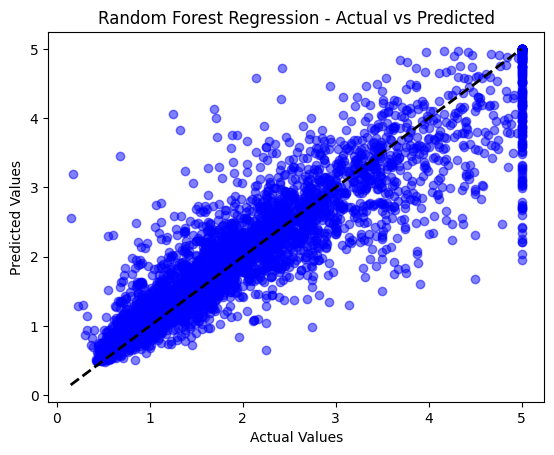

In [24]:
plt.scatter(y_test, y_pred_test, alpha=0.5, color="blue")
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Random Forest Regression - Actual vs Predicted")
plt.show()

Most predictions follow the diagonal, but the model pulls extreme values toward the middle, and the $500k cap creates the largest errors.

Good fit for most districts. The dense band of points follows the dashed line y = x from about 0.5 to 3 ($50k–$300k). In that range, predictions are mostly close to the real values.
A vertical column of points at actual = 5.0. These are the capped districts ($500,001). The model predicts anything from about 1.7 to 5.0 for them. Their true value is unknown above the cap, so the model can't learn a consistent pattern. These points contribute a large share of the RMSE.
The model pulls extreme values toward the average (regression to the mean).
Cheap districts are overestimated. At actual values below about 0.5, almost all points are above the line, and predictions rarely go below 0.5.
Expensive districts are underestimated. From about 3.5 upward, most points are below the line.
This is typical of Random Forest: each prediction is an average of training values, so it can never go beyond the minimum or maximum it saw, and it tends to shrink extremes.
The error grows with price. The cloud is narrow at low values and wider at high values. Predictions for expensive districts are less reliable than for cheap ones.
Some isolated large mistakes. For example, actual ≈ 0.2 predicted ≈ 3.2, or actual ≈ 2.3 predicted ≈ 0.65. These are probably unusual districts, such as the extreme AveRooms and AveOccup outliers in the summary table.

Average error = -1250
Standard deviation of error = 50583


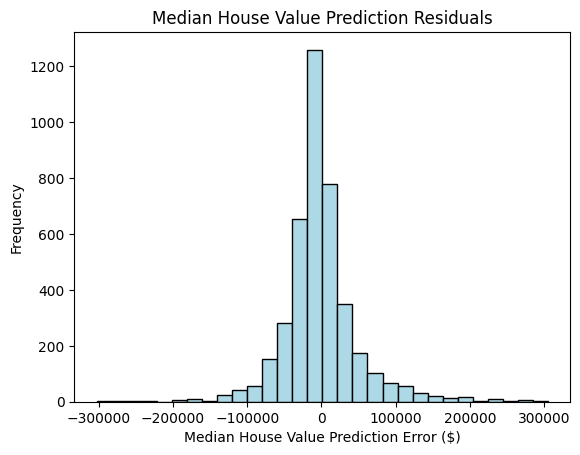

In [25]:
# Calculate the residual errors
residuals = 1e5*(y_test - y_pred_test)

# Plot the histogram of the residuals
plt.hist(residuals, bins=30, color='lightblue', edgecolor='black')
plt.title(f'Median House Value Prediction Residuals')
plt.xlabel('Median House Value Prediction Error ($)')
plt.ylabel('Frequency')
print('Average error = ' + str(int(np.mean(residuals))))
print('Standard deviation of error = ' + str(int(np.std(residuals))))

Errors are centred at 0 with no systematic bias, but the distribution has a sharp peak and long tails, especially on the positive side.

There's no systematic bias. The tallest bar (about 1,260 districts) is right at $0, and the distribution is roughly balanced around it. The model doesn't consistently over- or underestimate prices.
Most errors are small. The bulk of the residuals fall between about −$50k and +$50k. That fits the MAE of about $33k.
The peak is sharp and the tails are long. The centre is much taller and narrower than a normal distribution, with tails that stretch to ±$300k. Most predictions are very accurate, but a minority are badly off, which explains why RMSE (≈ $50.6k) is clearly higher than MAE.
The positive tail is heavier. The right side has more mass from about +$50k to +$200k than the left side has from −$50k to −$200k. So the model underestimates more often than it overestimates when it makes large errors. This is the pattern from the actual-vs-predicted plot: expensive districts, especially the capped ones at $500k, get predictions that are too low.
Very large errors are rare. Only a few districts have errors beyond ±$150k, but each one of them weighs heavily on RMSE.

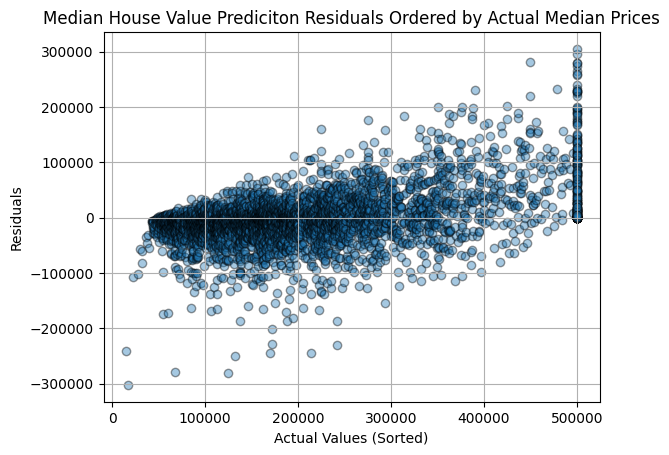

In [26]:
residuals_df = pd.DataFrame({
    'Actual': 1e5*y_test,
    'Residuals': residuals
})

# Sort the DataFrame by the actual target values
residuals_df = residuals_df.sort_values(by='Actual')

# Plot the residuals
plt.scatter(residuals_df['Actual'], residuals_df['Residuals'], marker='o', alpha=0.4,ec='k')
plt.title('Median House Value Prediciton Residuals Ordered by Actual Median Prices')
plt.xlabel('Actual Values (Sorted)')
plt.ylabel('Residuals')
plt.grid(True)
plt.show()

The residuals trend upward. At low prices the cloud sits slightly below 0 (overestimation). Around $150k–$250k it's centred near 0, and from about $300k upward it shifts clearly above 0 (underestimation). That's a systematic bias that depends on price: the model pulls extreme values toward the middle (regression to the mean), as in the actual-vs-predicted plot.
The spread grows with price (heteroscedasticity). Below $100k, most residuals are within about ±$50k. Above $300k, they range from about −$100k to +$200k. The model is much less precise for expensive districts.
The $500k column is all positive. For the capped districts, residuals go from 0 to about +$300k. The model never overestimates them, because Random Forest can't predict above the maximum it saw in training. These points produce the largest errors in the whole model.
There are large overestimates at the low end. A few cheap districts (actual ≈ $15k–$130k) get residuals of −$200k to −$300k: the model predicted them at $250k–$400k. These are likely unusual districts, such as the extreme AveRooms/AveOccup outliers.
Small errors are concentrated in the middle range. Below about $250k the cloud is densest and tightest. That's where most districts are, and why MAE is only about $33k overall.